# 02 – Osnovni vizualizaciji

Dve enostavni vizualizaciji za prvi pregled podatkov, preden gremo v podrobnejšo analizo (`03_teden5_vizualizacije.ipynb`).

**Primerljiv nabor:** samo hoteli (BFS ima samo hotele, pri ASTAT vzamemo kategorijo `A`), Južna Tirolska (ASTAT) in Švica (BFS), obdobje 2013–2025.
ISTAT tu izpustimo, ker nima ločenih hotelov in pokriva le 2022–2025; zadnje leto 2026 je nepopolno.

**Smučarske občine:** občine z nadmorsko višino vsaj `ALT_MIN = 1000 m` (odprta odločitev iz `PLAN.md`, prag lahko spremenimo).
Pri Švici je višina za del občin dvoumna (vzamemo najnižjo vrednost iz Wikidata), zato je razvrstitev tam približna.

Obdržimo le občine, ki imajo podatek za vsaj 95 % mesecev (brez let 2020–2021, ko so bili hoteli zaradi covida pogosto zaprti ali zaupni).

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
ALT_MIN = 1000          # elevation threshold for "ski-capable" municipalities, metres
YEARS = (2013, 2025)    # common complete window of ASTAT and BFS
COVID = [2020, 2021]

# one colour per country, used the same way in every chart
COLORS = {"IT": "#2a78d6", "CH": "#eb6834"}
LABELS = {"IT": "Italija (Južna Tirolska)", "CH": "Švica"}

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#9a9893", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})
millions = FuncFormatter(lambda v, _: f"{v / 1e6:.1f} M")

In [2]:
df = pd.read_csv(ROOT / "data/processed/tourism_monthly.csv", dtype={"muni_id": str}, parse_dates=["date"])
hot = df[(df["scope"] == "hotel") & df["year"].between(*YEARS)].copy()

# completeness filter: at least 95 % of non-COVID months observed
normal = hot[~hot["year"].isin(COVID)]
n_months = normal["date"].nunique()
coverage = normal.groupby(["country", "muni_id"])["overnights"].count() / n_months
keep = coverage[coverage >= 0.95].index
hot = hot.set_index(["country", "muni_id"]).loc[keep].reset_index()

hot["high"] = hot["elev_m"] >= ALT_MIN

# series used by the charts below: monthly sum over high municipalities, average seasonal profile
high = hot[hot["high"]]
monthly = high.groupby(["country", "date"])["overnights"].sum(min_count=1).unstack("country")
h = hot[~hot["year"].isin(COVID)]
agg = h.groupby(["high", "country", "year", "month"])["overnights"].sum(min_count=1).reset_index()
agg["share"] = agg["overnights"] / agg.groupby(["high", "country", "year"])["overnights"].transform("sum")
profile = agg.groupby(["high", "country", "month"])["share"].mean().unstack("country")
(hot.drop_duplicates(["country", "muni_id"])
    .groupby(["country", "high"]).size().unstack()
    .rename(columns={False: f"< {ALT_MIN} m", True: f">= {ALT_MIN} m"}))

high,< 1000 m,>= 1000 m
country,,
CH,133,40
IT,62,44


## 1. Mesečne prenočitve v smučarskih občinah skozi čas

Vsota hotelskih prenočitev v občinah nad pragom, po mesecih. Vidimo sezonski vzorec (dva vrhova na leto), padec v času covida in okrevanje po njem.

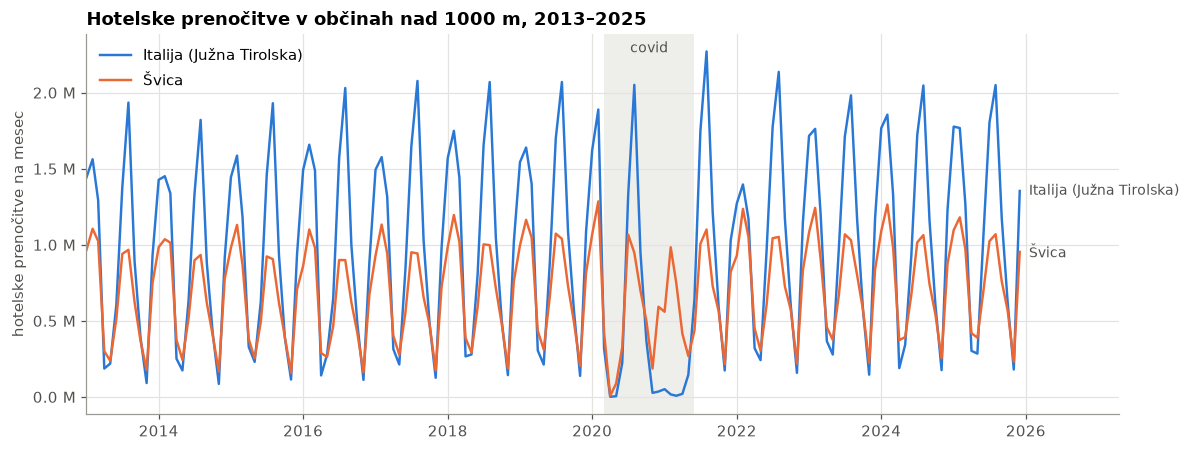

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.2))
for c in ["IT", "CH"]:
    ax.plot(monthly.index, monthly[c], color=COLORS[c], lw=1.6, label=LABELS[c])
    ax.annotate(LABELS[c], (monthly.index[-1], monthly[c].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color="#52514e", fontsize=9)

ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-06-01"), color="#e4e3df", alpha=0.6, lw=0)
ax.text(pd.Timestamp("2020-10-15"), ax.get_ylim()[1] * 0.95, "covid", ha="center", color="#52514e", fontsize=9)
ax.yaxis.set_major_formatter(millions)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_ylabel("hotelske prenočitve na mesec")
ax.set_title(f"Hotelske prenočitve v občinah nad {ALT_MIN} m, {YEARS[0]}–{YEARS[1]}", loc="left")
ax.legend(loc="upper left", frameon=False)
ax.set_xlim(monthly.index[0], monthly.index[-1] + pd.Timedelta(days=500))
plt.tight_layout()
plt.show()

In [4]:
# highest and lowest month per country (excluding the COVID years)
m = monthly[~monthly.index.year.isin(COVID)]
pd.DataFrame({c: {"max month": f"{m[c].idxmax():%Y-%m}", "max": int(m[c].max()),
                  "min month": f"{m[c].idxmin():%Y-%m}", "min": int(m[c].min())} for c in m})

,CH,IT
max month,2024-02,2022-08
max,1264459,2136675
min month,2015-11,2014-11
min,157500,85628


**Opažanja:**
- Obe državi imata dva vrhunca na leto: zimskega (januar–marec) in poletnega (julij–avgust). Najnižji meseci so april–maj in november, ko smučarska sezona še ni začela ali je že končana; najnižji mesec v obeh državah je november.
- V Južni Tirolski je poletni (avgustovski) vrh višji od zimskega; v Švici je zimski vrh malo višji od poletnega. Najvišji mesec v Švici je februar 2024, v Južni Tirolski avgust 2022.
- Spomladi 2020 in pozimi 2020/21 hoteli skoraj ne beležijo prenočitev. V Italiji je bila zima 2020/21 v celoti izgubljena (smučišča zaprta), v Švici so smučišča ostala odprta, zato je padec manjši.
- Poletji 2020 in 2021 sta v Južni Tirolski skoraj normalni (2021 celo rekordni), ker so ljudje dopustovali v bližini doma.

## 2. Povprečni sezonski profil: visoke in nizke občine

Za vsako leto izračunamo delež letnih prenočitev, ki odpade na posamezen mesec, in ga povprečimo čez leta (brez 2020–2021).
Tako primerjamo **obliko** sezone ne glede na velikost občin. Levo občine nad pragom, desno ostale.

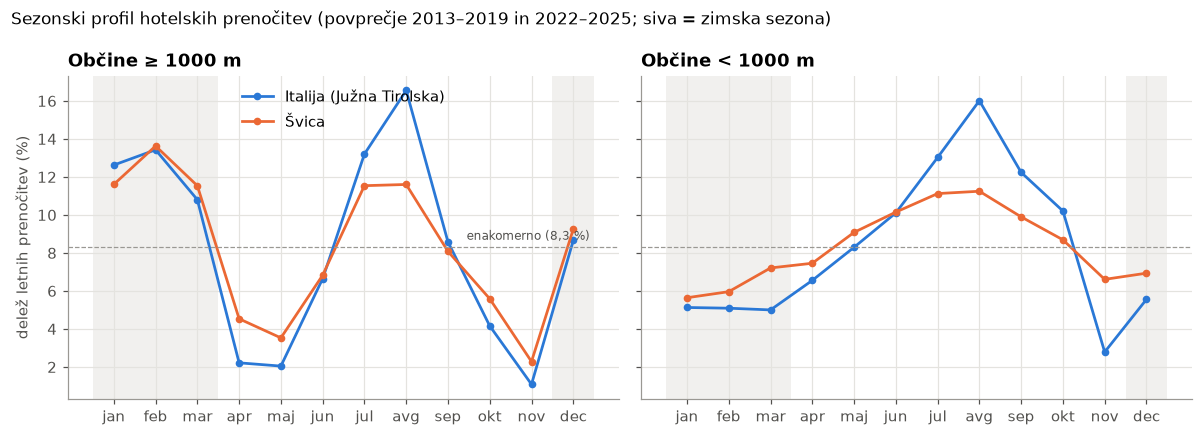

In [5]:
MONTHS = ["jan", "feb", "mar", "apr", "maj", "jun", "jul", "avg", "sep", "okt", "nov", "dec"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, is_high, title in [(axes[0], True, f"Občine ≥ {ALT_MIN} m"), (axes[1], False, f"Občine < {ALT_MIN} m")]:
    p = profile.loc[is_high]
    ax.axvspan(0.5, 3.5, color="#e4e3df", alpha=0.5, lw=0)   # Jan-Mar
    ax.axvspan(11.5, 12.5, color="#e4e3df", alpha=0.5, lw=0)  # Dec
    for c in ["IT", "CH"]:
        ax.plot(p.index, p[c] * 100, color=COLORS[c], lw=1.8, marker="o", ms=4, label=LABELS[c])
    ax.axhline(100 / 12, color="#9a9893", lw=0.8, ls="--")
    ax.set_xticks(range(1, 13), MONTHS)
    ax.set_title(title, loc="left")
axes[0].set_ylabel("delež letnih prenočitev (%)")
axes[0].text(12.4, 100 / 12 + 0.2, "enakomerno (8,3 %)", ha="right", va="bottom", fontsize=8, color="#52514e")
axes[0].legend(frameon=False, loc="upper center")
fig.suptitle("Sezonski profil hotelskih prenočitev (povprečje 2013–2019 in 2022–2025; siva = zimska sezona)",
             x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()

In [6]:
# winter share (Dec-Mar) of annual overnights, in %
winter = profile.loc[:, :].reset_index()
winter = (winter[winter["month"].isin([12, 1, 2, 3])].groupby("high")[["IT", "CH"]].sum() * 100).round(1)
winter.index = winter.index.map({True: f">= {ALT_MIN} m", False: f"< {ALT_MIN} m"})
winter

country,IT,CH
high,,
< 1000 m,20.8,25.7
>= 1000 m,45.5,46.0


**Opažanja:**
- Visoke občine so izrazito dvosezonske: december–marec prinese okoli 46 % letnih prenočitev v obeh državah (pri enakomerni porazdelitvi bi bila tretjina). V nizkih občinah je ta delež le 21 % (Italija) oz. 26 % (Švica); te občine so poletne.
- Med visokimi občinami sta profila obeh držav skoraj enaka pozimi; razlika je izven zime: Južna Tirolska ima močnejši avgust in globlji upad aprila–maja in novembra, švicarski hoteli pa imajo bolj enakomerno predsezono in posezono.
- Pri nizkih občinah je razlika večja: Južna Tirolska ima oster poletni vrh, Švica precej bolj enakomerno leto (verjetno zaradi mestnega in poslovnega turizma, npr. Zürich, Ženeva).
- Ti dve sliki sta izhodišče za teden 5: kako je zimski delež povezan z nadmorsko višino, kako stabilne so posamezne sezone in kako se naši rezultati ujemajo z objavljenimi analizami.